# EDS 220 HW 4 - Task 2: Fire Scars Through False Color

Kailani Latimer

11/19/2026

[GitHub repository](https://github.com/kailani-boop/eds220-hwk4)

## About

### Purpose
This notebook uses Landsat 8 imagery to visualize the burn scars from the January 2025 Palisades and Eaton fires in Los Angeles County. It compares a true color image to a false color (SWIR/NIR/red) image and maps the false color image with both fire perimeters.

### Highlights
- Restoring geospatial information to a NetCDF dataset using `rioxarray`
- Creating true color and false color images with `xarray`, including handling NaN values and color scaling
- Reprojecting fire perimeter data so it matches the Landsat CRS
- Mapping fire perimeters over false color imagery to highlight burn scars

### About the data
- **Landsat 8 imagery:** A clipped subset of Landsat 8 Collection 2 Level-2 surface reflectance data from February 23, 2025, containing red, green, blue, near-infrared, and shortwave infrared bands. Accessed through the Microsoft Planetary Computer and shared via the EDS 220 course Google Drive. For visualization and educational purposes only.
- **Fire perimeters:** GeoJSON files of the Eaton and Palisades fire perimeters (January 21, 2025) from the LA County Enterprise GIS "Palisades and Eaton Dissolved Fire Perimeters (2025)" dataset, sourced from CAL FIRE.

### References
- EDS 220 Assignment 4 instructions: [https://meds-eds-220.github.io/MEDS-eds-220-course/assignments/assignment4-palisades-eaton-fires.html](https://meds-eds-220.github.io/MEDS-eds-220-course/assignments/assignment4-palisades-eaton-fires.html)
- U.S. Geological Survey. (2020). *Landsat 8-9 Operational Land Imager / Thermal Infrared Sensor Level-2, Collection 2* [Dataset]. Accessed via Microsoft Planetary Computer. [https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2)
- Microsoft Open Source, McFarland, M., Emanuele, R., Morris, D., & Augspurger, T. (2022). *microsoft/PlanetaryComputer: October 2022* (2022.10.28). Zenodo. [https://doi.org/10.5281/zenodo.7261897](https://doi.org/10.5281/zenodo.7261897)
- Los Angeles County Enterprise GIS. (2025). *Palisades and Eaton dissolved fire perimeters (2025)* [Dataset]. Data source: CAL FIRE. Retrieved November 19, 2026, from https://egis-lacounty.hub.arcgis.com/datasets/ad51845ea5fb4eb483bc2a7c38b2370c
- Riebeek, H. (2014). *Why is that forest red and that cloud blue? How to interpret a false-color satellite image.* NASA Earth Observatory. [https://earthobservatory.nasa.gov/features/FalseColor](https://earthobservatory.nasa.gov/features/FalseColor)
- U.S. Geological Survey. *What are the band designations for the Landsat satellites?* [https://www.usgs.gov/faqs/what-are-band-designations-landsat-satellites](https://www.usgs.gov/faqs/what-are-band-designations-landsat-satellites)
- U.S. Geological Survey. *Common Landsat band combinations.* [https://www.usgs.gov/media/images/common-landsat-band-combinations](https://www.usgs.gov/media/images/common-landsat-band-combinations)

## 1. Setup

First, we import the packages we need and load the fire perimeter and Landsat data.

In [1]:
# Importing packages
import os                        # build file paths
import numpy as np               # np.isnan() to find NaN values (section 5)
import geopandas as gpd          # read + work with the fire perimeters (vector data)
import xarray as xr              # open the Landsat .nc file (raster data)
import rioxarray                 # adds .rio to xarray: .rio.crs, .rio.write_crs() (section 4)
import matplotlib.pyplot as plt  # make the final map

In [2]:
# Load in the data
eaton = gpd.read_file(os.path.join('data', 'Eaton_Perimeter_20250121.geojson'))
pali = gpd.read_file(os.path.join('data', 'Palisades_Perimieter_20250121.geojson'))
landsat = xr.open_dataset(os.path.join('data', 'landsat8-2025-02-23-palisades-eaton.nc'))

## 2. Fire Perimeter Data Exploration

Next, we take a quick look at each fire perimeter dataset: its CRS and what the perimeter looks like. 

CRS: PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


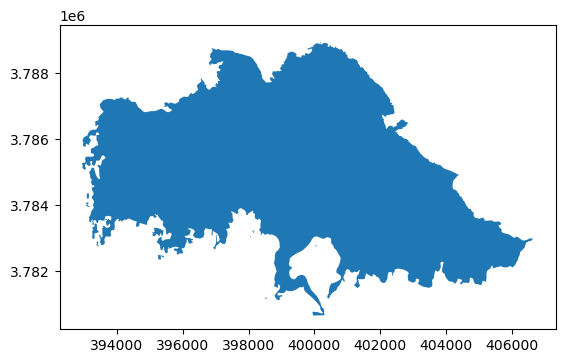

In [21]:
# Exploring the Eaton data
print('CRS:', eaton.crs)
eaton.plot()
plt.show()

CRS: PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


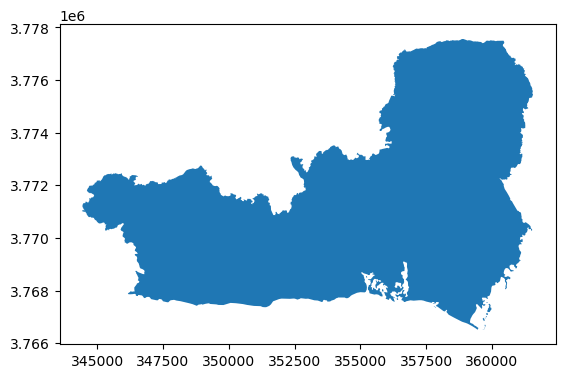

In [22]:
# Exploring the Palisades data
print('CRS:', pali.crs)
pali.plot()
plt.show()

We check whether the CRS is projected or geographic, and look at the attribute table for each perimeter. 

In [5]:
# Is CRS projected or geographic? 
print('Eaton projected:', eaton.crs.is_projected)
print('Palisades projected:', pali.crs.is_projected)

# Looking at the attributes
print(eaton.head())
print(pali.head())

Eaton projected: False
Palisades projected: False
   OBJECTID  YEAR_ STATE AGENCY UNIT_ID FIRE_NAME            type   INC_NUM  \
0         1   2025    CA    CDF     LAC     EATON  Heat Perimeter  00009087   

                                  IRWINID                ALARM_DATE  ...  \
0  {72660ADC-B5EF-4D96-A33F-B4EA3740A4E3} 2025-01-08 00:00:00+00:00  ...   

  GIS_ACRES  COMMENTS  COMPLEX_NAME  COMPLEX_ID  FIRE_NUM  \
0  14056.26      None          None        None      None   

                               GlobalID    DECADES Shape__Area Shape__Length  \
0  000a99c2-0fef-4960-a3c4-f2342a0cd291  2020-2025    0.005564      0.859026   

                                            geometry  
0  MULTIPOLYGON (((-118.10094 34.16681, -118.1009...  

[1 rows x 24 columns]
   OBJECTID  YEAR_ STATE AGENCY UNIT_ID  FIRE_NAME            type   INC_NUM  \
0         1   2025    CA    CDF     LDF  PALISADES  Heat Perimeter  00000738   

                                  IRWINID                ALA

Each file contains a single MultiPolygon with 24 attribute columns, including the fire name, alarm date, and burned area. The Palisades fire started January 7, 2025 and burned about 23,449 acres, while the Eaton fire started January 8, 2025 and burned about 14,056 acres.

#### Fire perimeter summary: 

The Eaton and Palisades fire perimeters are each stored as GeoJSON files and read in as GeoDataFrames. Both use the CRS EPSG:4326 (WGS 84), which is a geographic CRS, meaning coordinates are in degrees of latitude and longitude rather than meters. Plotting each dataset shows the outline of the burned area for each fire. Because the Landsat data uses a projected CRS (see below), the fire perimeters will need to be reprojected to match before mapping them together.

## 3. NetCDF Data Import and Exploration

Now we explore the Landsat data, which is stored as a NetCDF file and loaded as an `xarray.Dataset`. We look at its variables, dimensions, and coordinates.

In [6]:
# Exploring landsat data
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

In [7]:
# Summary of dimensions, variables, and attributes (including the CRS stored in spatial_ref)
landsat.info()

xarray.Dataset {
dimensions:
	y = 1418 ;
	x = 2742 ;

variables:
	float64 y(y) ;
		y:units = metre ;
		y:resolution = -30.0 ;
		y:crs = EPSG:32611 ;
		y:axis = Y ;
		y:long_name = y coordinate of projection ;
		y:standard_name = projection_y_coordinate ;
	float64 x(x) ;
		x:units = metre ;
		x:resolution = 30.0 ;
		x:crs = EPSG:32611 ;
		x:axis = X ;
		x:long_name = x coordinate of projection ;
		x:standard_name = projection_x_coordinate ;
	datetime64[ns] time() ;
	float32 red(y, x) ;
		red:grid_mapping = spatial_ref ;
	float32 green(y, x) ;
		green:grid_mapping = spatial_ref ;
	float32 blue(y, x) ;
		blue:grid_mapping = spatial_ref ;
	float32 nir08(y, x) ;
		nir08:grid_mapping = spatial_ref ;
	float32 swir22(y, x) ;
		swir22:grid_mapping = spatial_ref ;
	int64 spatial_ref() ;
		spatial_ref:crs_wkt = PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["

In [8]:
# Coordinates: x and y (in meters) plus a single time value
landsat.coords

Coordinates:
  * y        (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x        (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time     datetime64[ns] 8B ...

In [9]:
# Dimensions: size of the y and x grid
landsat.dims

FrozenMappingWarningOnValuesAccess({'y': 1418, 'x': 2742})

In [10]:
# Data variables: the spectral bands and spatial_ref
landsat.data_vars

Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

#### Landsat summary: 

The Landsat data is an `xarray.Dataset` loaded from a NetCDF file. It has two dimensions, y (1,418) and x (2,742), so each band is a 1,418 × 2,742 grid of pixels. The coordinates are x and y, measured in meters with a 30 m resolution, plus a single time value. The data variables are five spectral bands (`red`, `green`, `blue`, `nir08`, and `swir22`) stored as float32, and a `spatial_ref` variable that holds the CRS information. The `spatial_ref` attributes show the data is in WGS 84 / UTM zone 11N (EPSG:32611), a projected CRS. However, the dataset is not yet recognized as a geospatial object by `rioxarray`, so the CRS needs to be restored in the next step.

## 4. Restoring Geospatial Information

The Landsat data has CRS information stored in it, but `rioxarray` doesn't recognize it yet. In this section we check the CRS, find where it's stored, and restore it so the data can be used as a geospatial object.

In [11]:
# a. Print the CRS recognized by rioxarray
print(landsat.rio.crs)  # returns None because the CRS isn't recognized yet

None


In [12]:
# b. Print the CRS stored in the spatial_ref variable
print(landsat.spatial_ref.crs_wkt)

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


The CRS info exists in the file, but it’s stored as a plain attribute. That’s why `landsat.rio.crs` returned `None` in 4a: `rioxarray` doesn’t recognize this attribute as the CRS.

To fix this, we use `rio.write_crs()` to apply the CRS stored in `spatial_ref`, then check that it worked.

In [13]:
# c. Restore the CRS using the WKT string stored in spatial_ref
landsat = landsat.rio.write_crs(landsat.spatial_ref.crs_wkt)

In [14]:
# d. Print the updated CRS to check that it worked
print(landsat.rio.crs) 

EPSG:32611


## 5. True Color Image

Next, we create a true color image by plotting the red, green, and blue bands. We start with a basic plot and then fix issues with color scaling and missing values.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


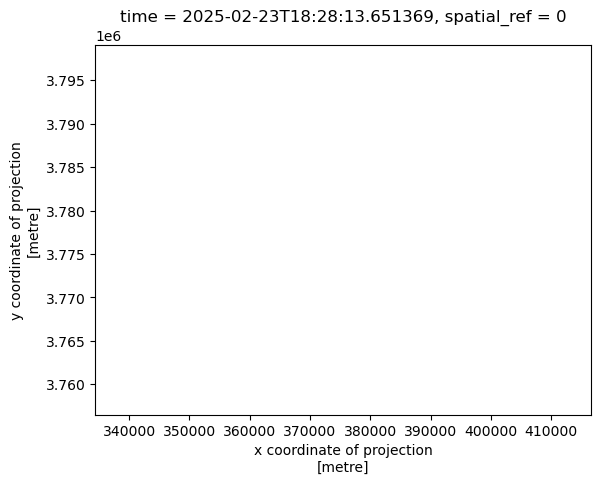

In [15]:
# a. Selecting certain variables, converting to data array, and then plotting it
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

The first plot is almost all white, so we use `robust = True` to rescale the colors.

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


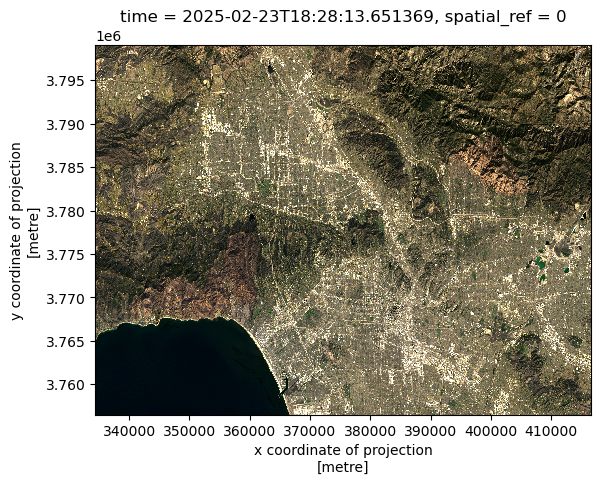

In [16]:
# b. Adjust the scale used for plotting the bands to get a true color image
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)

The plots also give a warning about invalid values, so we check which bands contain `NaN` values.

In [17]:
# c. Check each band for NaN values
for band in ['red', 'green', 'blue', 'nir08', 'swir22']:
    print(band, np.isnan(landsat[band]).any().values)

red False
green True
blue True
nir08 False
swir22 False


We replace the `NaN` values with 0 and re-plot to get a clean true color image without warnings.

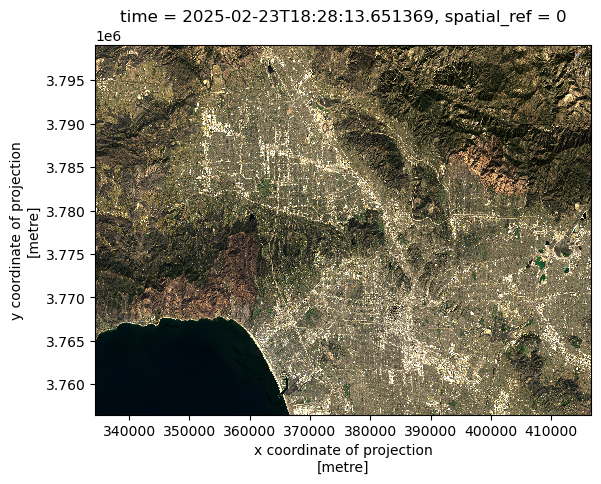

In [18]:
# d. Use the `.fillna()` method to replace any `nan` values with 0
landsat[['red', 'green', 'blue']].fillna(0).to_dataarray().plot.imshow(robust = True)

**e.** The first plot appeared almost completely white because the Landsat values are much larger than the 0–1 range `imshow` expects for float RGB data, so all values were clipped to 1. Setting `robust = True` rescales the colors using the 2nd–98th percentiles so outliers don’t wash out the image. Filling the `NaN` values with `0` removed the casting warning, resulting in a clear true color image of the Los Angeles area.

## 6. False Color Image

A false color image assigns non-visible bands to the red, green, and blue display channels. Here we plot shortwave infrared, near-infrared, and red, which makes burned areas stand out from healthy vegetation.

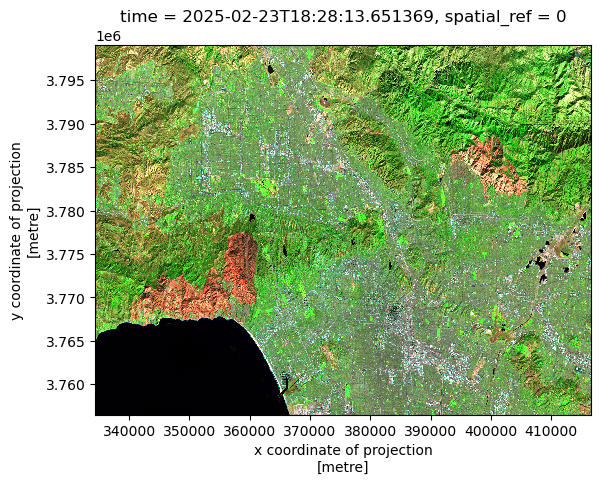

In [19]:
# Plot shortwave infrared, near-infrared, and red (in that order) as a false color image
landsat[['swir22', 'nir08', 'red']].fillna(0).to_dataarray().plot.imshow(robust = True)

## 7. Map

Finally, we map the false color image with both fire perimeters. The perimeters are first reprojected to the Landsat CRS so the two layers line up.

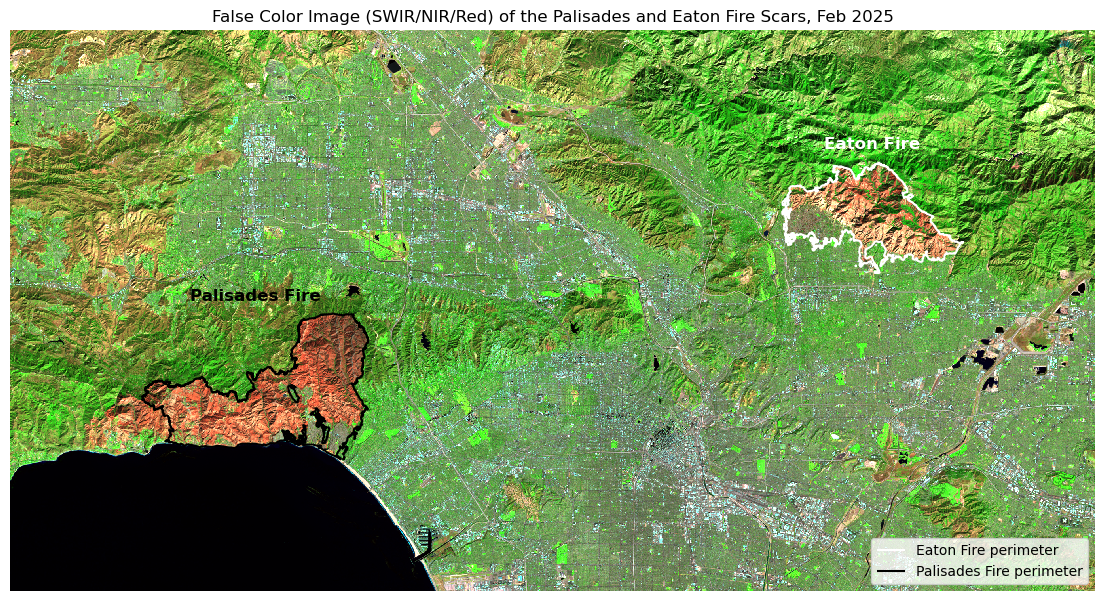

In [20]:
# a. Plot the fires together using the false color imaging
# Reproject fire perimeters to match the Landsat CRS
eaton = eaton.to_crs(landsat.rio.crs)
pali = pali.to_crs(landsat.rio.crs)

fig, ax = plt.subplots(figsize=(14, 8))

# False color image (SWIR, NIR, red)
landsat[['swir22', 'nir08', 'red']].to_dataarray().fillna(0).plot.imshow(ax=ax, robust=True)

# Fire perimeters (outlines only)
eaton.boundary.plot(ax=ax, color='white', linewidth=1.5, label='Eaton Fire perimeter')
pali.boundary.plot(ax=ax, color='black', linewidth=1.5, label='Palisades Fire perimeter')

# Label each fire above its perimeter
minx, miny, maxx, maxy = eaton.total_bounds
ax.text((minx + maxx) / 2, maxy + 1000, 'Eaton Fire', color='white',
        fontsize=12, fontweight='bold', ha='center')

minx, miny, maxx, maxy = pali.total_bounds
ax.text((minx + maxx) / 2, maxy + 1000, 'Palisades Fire', color='black',
        fontsize=12, fontweight='bold', ha='center')

# Legend, title, clean up axes
ax.legend(loc='lower right')
ax.set_title('False Color Image (SWIR/NIR/Red) of the Palisades and Eaton Fire Scars, Feb 2025')
ax.axis('off')

plt.show()

**b.** This map shows a false color composite of Landsat 8 imagery from February 23, 2025, about six weeks after the Palisades and Eaton fires, with each fire’s perimeter outlined. In this false color image, shortwave infrared (SWIR), near-infrared (NIR), and red bands are displayed as red, green, and blue. Healthy vegetation reflects strongly in NIR, so it appears bright green, while burned areas reflect more SWIR and less NIR, so they appear reddish-brown. Water absorbs these wavelengths and appears black, and urban areas appear gray. This makes burn scars stand out much more clearly than in a true color image. The reddish-brown burn scars line up closely with both fire perimeters. Parts of each perimeter that overlap neighborhoods appear gray instead of red, since burned buildings and pavement don’t reflect like burned vegetation. 